# Práctica 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

## Ejercicio 1

Sea un paquete de bits de longitud $L$:
$$B = (b_1, b_2, \dots, b_L)$$
donde la tasa de error (bit flip error rate) es $BER$ y el número de routers (encaminadores) es $n$.

$$Alice \xrightarrow{B} router_1 \xrightarrow{B_{[r_1]}} \dots \xrightarrow{B_{[r_1, \dots, r_{n - 1}]}} router_n \xrightarrow{B_{[r_1, \dots, r_{n}]}} Bob$$

donde $B_{[r_1, \dots, r_i]}$ representa el paquete $B$ después de ser reenviado por el los routers $1\dots i$ para $i\in \{1, \dots, n\}$. Vamos a suponer que los posibles errores se producen en los routers al reenviar los mensajes recibidos. Además, el primer envío no vamos a contar como retransmisión, por lo que el número de retransmisiones sería 
$$R = T - 1$$

donde $T$ es el número de envíos totales que vamos a estimar en este ejercicio.

Ahora, dado una probabilidad de éxito $e$ para una acción, el número de intentos estimados necesarios para obtener un éxito sería $1/e$.

Si tenemos que el ratio de error de un bit es $BER$, la probabilidad de que no haya error en el bit sería $e = 1 - BER$. Suponiendo que el error en cada bit es independiente uno del otro, la tasa de NO error en el paquete $B$ sería $e_B = e^{L}$. Además, si queremos que atraviese los n routers sin error, esa probabilidad sería $e_{B, n} = e_B^n = e^{L\cdot n}$. 

Por lo tanto la cantidad de transmisiones estimadas serían $T = 1/e_{B,n}$ y el número de retransmisiones $R = 1/e_{B,n} - 1$

In [25]:
def R(ber, l, n):
    exito = 1 - ber

    unEnvio = exito**(l) #probabilidad de que un paquete no tenga error
    
    pExito = unEnvio**n #probabilidad de que un paquete no tenga error al pasar por n routers

    return (1/(pExito)) - 1 #redondeamos para obtener un numero entero


In [26]:
print(R(0.001, 15, 100))

3.485053842140669


In [31]:
def retransmision_sim_geom(ber, n, l, tries,  seed = 42, seed_init = False):
    if seed_init:
        np.random.default_rng(seed)
    p_exito = (1 - ber) ** (l * n)
    return np.random.geometric(p_exito, size = tries) - 1


In [41]:
np.random.seed(99)
l = 1024
errors = [1e-3, 1e-4, 1e-5, 1e-6]
rows = [] #array vacio

n_tries = 100_000

In [42]:
for ber in errors:
    for i in range(1, 17):
        r = R(ber, l, i)
        sim_r = retransmision_sim_geom(ber, i, l, n_tries)

        mean_r = np.mean(sim_r)

        print(f'n = {i}, l = {l}, error = {ber}. Estimacion = {r} y simulacion = {mean_r}.')
        rows.append({"n": i, "error": ber, "estimation": r, "simulation": mean_r})

df = pd.DataFrame(rows)

n = 1, l = 1024, error = 0.001. Estimacion = 1.7857366413704816 y simulacion = 1.79135.
n = 2, l = 1024, error = 0.001. Estimacion = 6.760328635074092 y simulacion = 6.75373.
n = 3, l = 1024, error = 0.001. Estimacion = 20.61823182780248 y simulacion = 20.53738.
n = 4, l = 1024, error = 0.001. Estimacion = 59.22270052435093 y simulacion = 58.99072.
n = 5, l = 1024, error = 0.001. Estimacion = 166.7645834929657 y simulacion = 166.27477.
n = 6, l = 1024, error = 0.001. Estimacion = 466.34794736061207 y simulacion = 465.55021.
n = 7, l = 1024, error = 0.001. Estimacion = 1300.90830123174 y simulacion = 1305.31817.
n = 8, l = 1024, error = 0.001. Estimacion = 3625.773658445657 y simulacion = 3613.80637.
n = 9, l = 1024, error = 0.001. Estimacion = 10102.23627028934 y simulacion = 10108.78804.
n = 10, l = 1024, error = 0.001. Estimacion = 28143.95547456826 y simulacion = 28103.503.
n = 11, l = 1024, error = 0.001. Estimacion = 78403.43373524553 y simulacion = 78161.78957.
n = 12, l = 1024, 

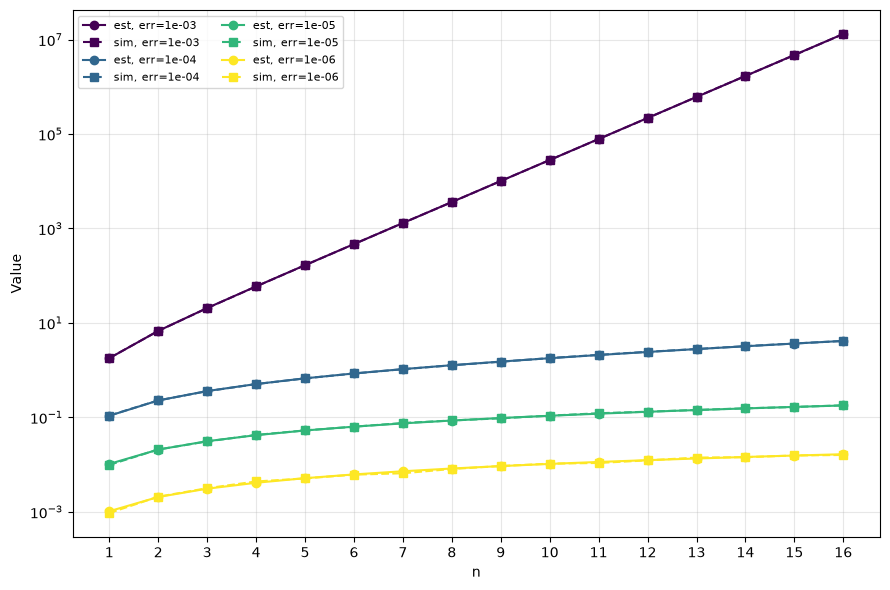

In [44]:
fig, ax = plt.subplots(figsize=(9, 6))

for err, color in zip(errors, plt.cm.viridis([0, 0.33, 0.66, 1.0])):
    sub = df[df["error"] == err].sort_values("n")
    ax.plot(sub["n"], sub["estimation"], color=color, marker="o",
            label=f"est, err={err:.0e}")
    ax.plot(sub["n"], sub["simulation"], color=color, marker="s", linestyle="--",
            label=f"sim, err={err:.0e}")

ax.set_yscale("log")                      # powers of 10 on the Y axis
ax.set_xlabel("n")
ax.set_ylabel("Value")
ax.set_xticks(range(1, 17))
ax.grid(alpha=0.3, which="both")
ax.legend(ncol=2, fontsize=8)   

fig.tight_layout()

fig.savefig(f'pr1_figs/classical_error_graphs.png', dpi=300, bbox_inches='tight')
plt.show()

## Ejercicio 2

In [2]:
I = np.array([[1, 0],[0, 1]], dtype=complex)
X = np.array([[0, 1],[1, 0]], dtype=complex)
Y = np.array([[0, -1j],[1j, 0]], dtype=complex)
Z = np.array([[1, 0],[0,-1]], dtype=complex)

### Ejercicio 2.1

Representamos el vector de Bloch

In [3]:
def density_matrix_to_BlochVector(rho: np.ndarray)-> np.ndarray:
    """
    rho = [a, b][c, d]

    rho = 1/2([1 + rz, rx - i*ry][rx + i*ry, 1 - rz])
    """
    a = rho[0, 0]
    c = rho[1, 0]

    rx = 2*c.real
    ry = 2*c.imag
    rz = 2.0*a - 1
    return np.array([rx, ry, rz], dtype = float)



def plot_bloch(rho, label=None, ax=None, elev=25, azim=-20, show=True):
    """
    Representa en 3D el vector de Bloch de una matriz de densidad 2x2.
 
    Vista: eje X hacia el observador, eje Y hacia la derecha, eje Z hacia arriba.
    (azim=0 es exactamente esa vista; azim=-20 la gira un poco para ver el 3D).
    """
    rho = np.asarray(rho, dtype=complex)
    if rho.shape != (2, 2):
        raise ValueError("La matriz de densidad debe ser 2x2.")
    if not np.isclose(np.trace(rho), 1):
        raise ValueError("La traza de rho debe ser 1.")
    if not np.allclose(rho, rho.conj().T):
        raise ValueError("rho debe ser hermítica.")
 
    rx, ry, rz = density_matrix_to_BlochVector(rho)
 
    if ax is None:
        fig = plt.figure(figsize=(7, 7))
        ax = fig.add_subplot(111, projection="3d")
 
    # Esfera de Bloch (malla)
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                      color="tab:blue", alpha=0.25, linewidth=0.4)
 
    # Vector de Bloch y punto final
    ax.quiver(0, 0, 0, rx, ry, rz, color="tab:blue", linewidth=2,
              arrow_length_ratio=0.08)
    ax.scatter([rx], [ry], [rz], s=50, color="tab:red", depthshade=False)
    ax.scatter([0], [0], [0], s=30, color="k")
    if label:
        ax.text(rx, ry, rz, " " + label, fontsize=9)
 
    # Ejes, planos (paneles) y vista
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("rx"); ax.set_ylabel("ry"); ax.set_zlabel("rz")
    ax.set_title("Bloch vector from density matrix")
    ax.view_init(elev=elev, azim=azim)
 
    if show:
        plt.show()
    return ax

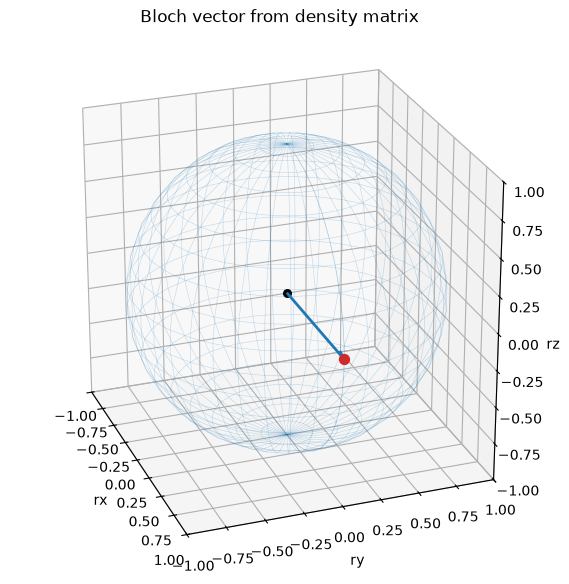

<Axes3D: title={'center': 'Bloch vector from density matrix'}, xlabel='rx', ylabel='ry', zlabel='rz'>

In [4]:
plus = np.array([[1], [1]]) / np.sqrt(2)
rho_puro = plus @ plus.conj().T #Representamos el |+>
plot_bloch(rho_puro)

### Ejercicio 2.2

Representaciones de las deformaciones de la esfera de Bloch

In [5]:
I2 = np.eye(2, dtype=complex)
 
 
# ---------- Canales de ruido (operadores de Kraus) ----------
def bit_flip(p):
    return [np.sqrt(1 - p) * I2, np.sqrt(p) * X]
 
 
def phase_flip(p):
    return [np.sqrt(1 - p) * I2, np.sqrt(p) * Z]
 
 
def depolarizing(p):
    # rho -> (1-p) rho + p I/2   (equivale a Pauli con prob. 3p/4 repartida)
    q = 3 * p / 4
    return [np.sqrt(1 - q) * I2, np.sqrt(q / 3) * X,
            np.sqrt(q / 3) * Y, np.sqrt(q / 3) * Z]
 
 
def apply_channel(rho, kraus):
    return sum(K @ rho @ K.conj().T for K in kraus)
 
 
# ---------- Deformación de la esfera ----------
def deformed_sphere(kraus, n=40):
    """Aplica el canal a puntos de la superficie de la esfera (estados puros)
    y devuelve las coordenadas (X, Y, Z) de la superficie resultante."""
    theta, phi = np.mgrid[0:np.pi:n * 1j, 0:2 * np.pi:n * 1j]
    X = np.zeros_like(theta); Y = np.zeros_like(theta); Z = np.zeros_like(theta)
    for i in range(n):
        for j in range(n):
            t, f = theta[i, j], phi[i, j]
            psi = np.array([np.cos(t / 2), np.exp(1j * f) * np.sin(t / 2)])
            rho = np.outer(psi, psi.conj())
            X[i, j], Y[i, j], Z[i, j] = density_matrix_to_BlochVector(apply_channel(rho, kraus))
    return X, Y, Z
 
 
def plot_noise_deformation(outfile, p=0.4, elev=25, azim=-20, show=True):
    """
    Dibuja, para un valor de p, la esfera de Bloch deformada por:
    a) bit flip, b) phase flip, c) depolarizing.
    Vista: X hacia el observador, Y hacia la derecha, Z hacia arriba.
    """
    channels = [("a) Bit flip", bit_flip(p), "tab:red"),
                ("b) Phase flip", phase_flip(p), "tab:green"),
                ("c) Depolarizing", depolarizing(p), "tab:purple")]
 
    # esfera original (referencia)
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    sx, sy, sz = np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)
 
    fig = plt.figure(figsize=(18, 6))
    for k, (title, kraus, color) in enumerate(channels, start=1):
        ax = fig.add_subplot(1, 3, k, projection="3d")
        ax.plot_wireframe(sx, sy, sz, color="gray", alpha=0.2, linewidth=0.4)
        X, Y, Z = deformed_sphere(kraus)
        ax.plot_surface(X, Y, Z, color=color, alpha=0.45, linewidth=0)
        ax.plot_wireframe(X, Y, Z, color=color, alpha=0.5, linewidth=0.3,
                          rstride=2, cstride=2)
        # ejes de la esfera
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_box_aspect((1, 1, 1))
        ax.set_xlabel("rx"); ax.set_ylabel("ry"); ax.set_zlabel("rz")
        ax.set_title(f"{title} (p = {p})")
        ax.view_init(elev=elev, azim=azim)
 
    fig.suptitle("Bloch Sphere deformation under noise")
    plt.tight_layout()

    fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()

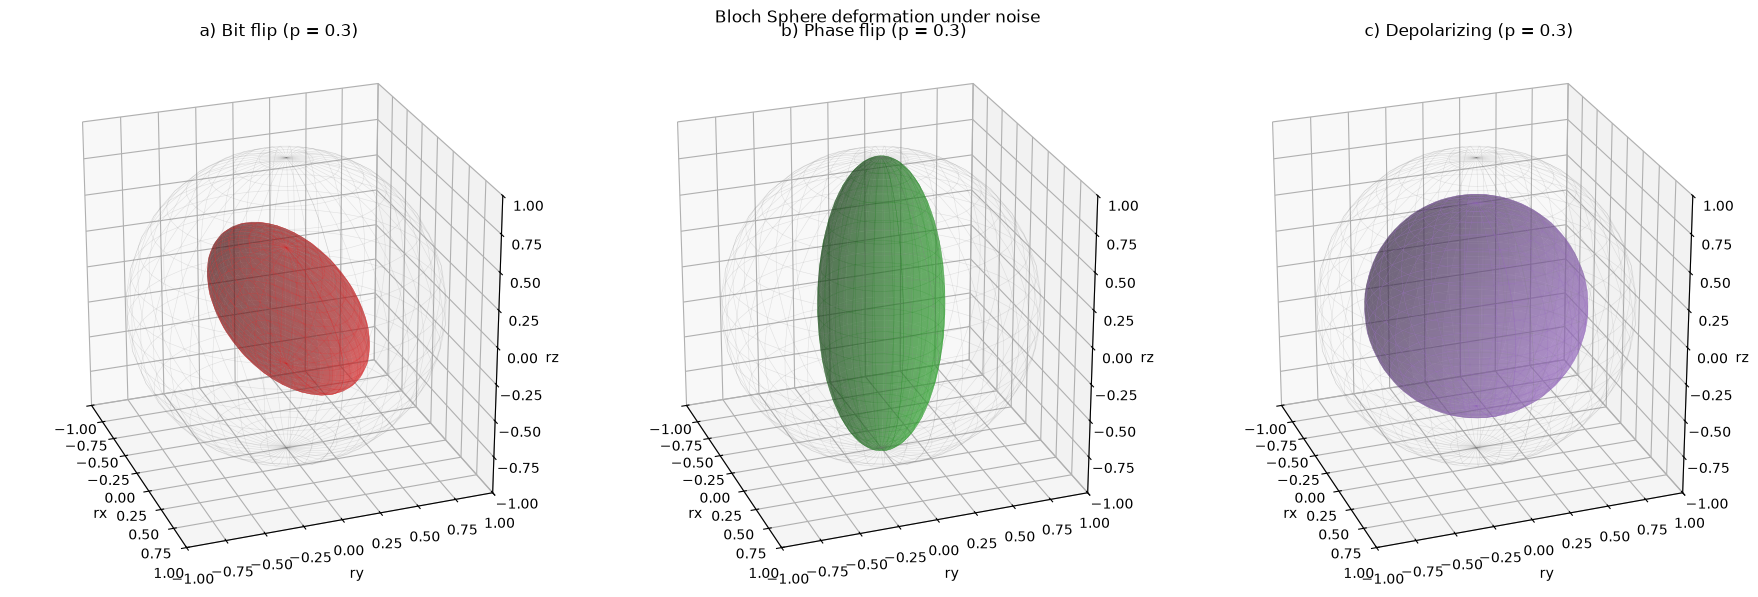

In [6]:
prob = 0.3

plot_noise_deformation(outfile = f'pr1_figs/bloch_sphere_deformation1.png', p=prob)

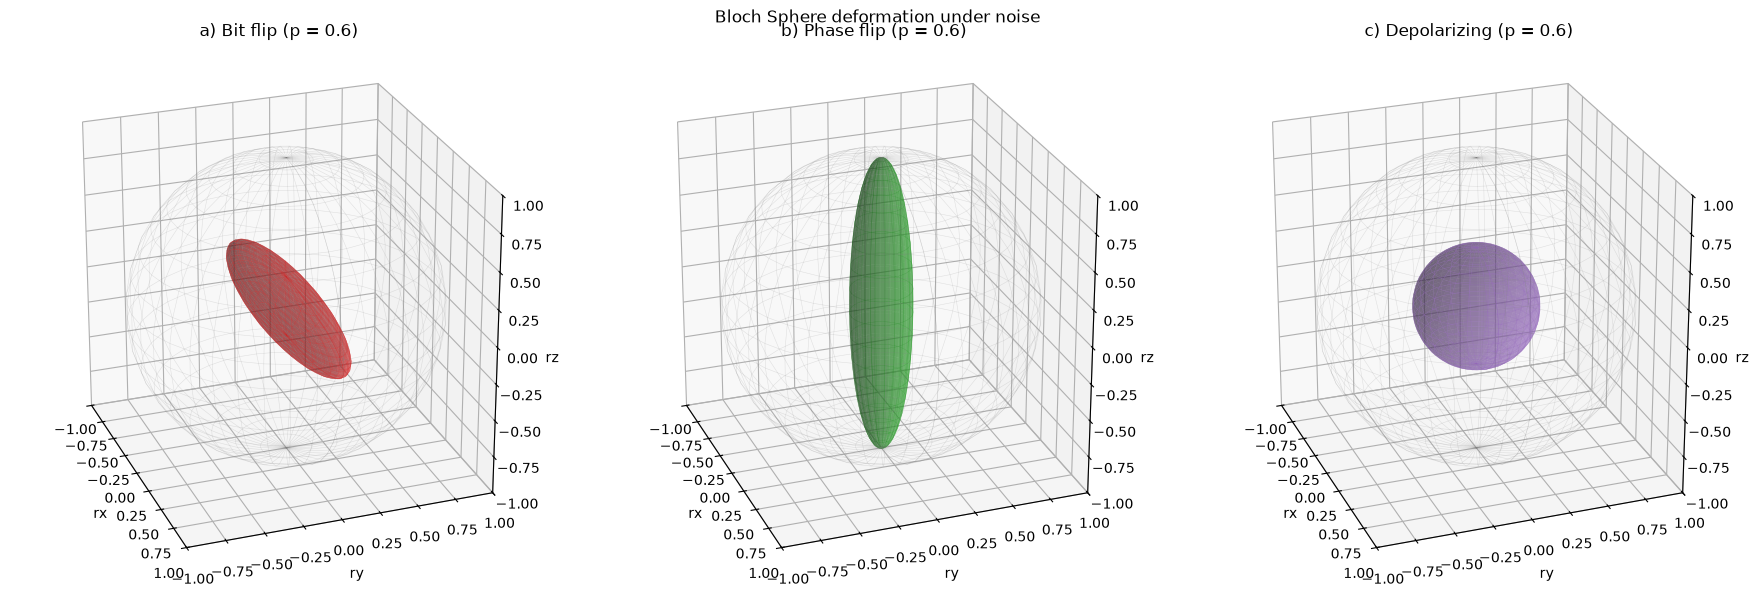

In [7]:
prob = 0.6

plot_noise_deformation(outfile = f'pr1_figs/bloch_sphere_deformation2.png', p=prob)